In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# CyberSentryFusion — Data Exploration

## 1. Objective

The objective of this notebook is to explore the UNSW-NB15 dataset and understand its structure, features, data types, and class distribution before building a machine learning model for network intrusion detection.

## 2. Dataset Overview

UNSW-NB15 contains network traffic records that can be used to distinguish normal network activity from potentially malicious activity.

This project uses supervised binary classification:

* **0 — Normal:** Network traffic classified as normal.
* **1 — Attack:** Network traffic classified as an attack.

## 3. Notebook Workflow

1. Import the required libraries.
2. Load the training and testing datasets.
3. Inspect the dataset structure and feature types.
4. Check for missing values and duplicate records.
5. Analyze the target variable and class distribution.
6. Explore numerical and categorical features.
7. Identify potential data quality issues before preprocessing and model training.

**Important:** The testing dataset will remain separate from model development and will be reserved for final evaluation.


## 4. Importing Libraries

We use the following Python libraries for data exploration and visualization:

* **Pandas:** Loads and analyzes tabular data.
* **NumPy:** Supports numerical computations.
* **Matplotlib:** Creates plots and charts.
* **Seaborn:** Creates statistical visualizations.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 5. Loading the Dataset

The UNSW-NB15 dataset is provided as separate training and testing CSV files.

We use `pandas.read_csv()` to load each file into a Pandas DataFrame.

* `train_df` stores the training dataset.
* `test_df` stores the testing dataset.

Keeping the test dataset separate helps prevent information from the final evaluation data from influencing model development.


In [6]:

train_path = "/kaggle/input/datasets/uzairsidd/cyber-sentry-dataset/UNSW_NB15_training-set.csv"

test_path = "/kaggle/input/datasets/uzairsidd/cyber-sentry-dataset/UNSW_NB15_testing-set.csv"

train_df = pd.read_csv(train_path)
test_df =  pd.read_csv(test_path)



## 6. Dataset Dimensions

The .shape attribute returns the number of rows and columns in a DataFrame.

The training dataset contains 175,341 records, while the testing dataset contains 82,332 records. Both datasets initially contain 45 columns.

Each row represents a network traffic record, and each column represents a feature or other information associated with that record.

Further inspection is required to identify the target variable and distinguish it from the input features.

In [7]:
print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

Training dataset shape: (175341, 45)
Testing dataset shape: (82332, 45)


## 7. Inspecting Dataset Columns

Before performing data analysis, we need to identify the available columns, understand their meanings, and locate the target variable.

The target variable is the value our machine learning model will learn to predict.


In [8]:
print("Training dataset columns:")
print(train_df.columns.tolist())

Training dataset columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']


## 8. Checking the Target Variable

The `label` column indicates whether network traffic is normal or an attack. We will check its unique values before analyzing the class distribution.


In [9]:
print("Unique labels:", train_df["label"].unique())

Unique labels: [0 1]


## 9. Class Distribution

Let's check how many records belong to each class. This will help us understand the balance between normal traffic and attack traffic in the training dataset.


In [10]:
print(train_df["label"].value_counts())

label
1    119341
0     56000
Name: count, dtype: int64


## 10. Class Distribution Percentage

The training dataset contains more attack records than normal records. We will calculate the percentage of each class to understand the class distribution more clearly.


In [11]:
class_percentage = train_df["label"].value_counts(normalize=True) * 100

print(class_percentage.round(2))

label
1    68.06
0    31.94
Name: proportion, dtype: float64


## 11. Visualizing Class Distribution

A bar chart makes it easier to compare the number of normal and attack records in the training dataset.


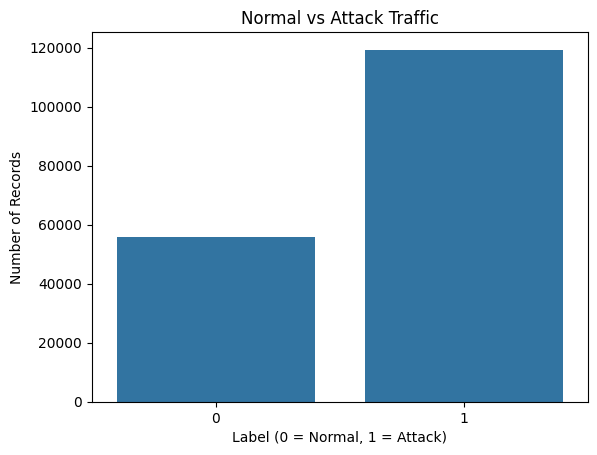

In [13]:
sns.countplot(data=train_df, x="label")

plt.title("Normal vs Attack Traffic")
plt.xlabel("Label (0 = Normal, 1 = Attack)")
plt.ylabel("Number of Records")
plt.show()

## 12. Checking Missing Values

Missing values can affect data preprocessing and model training. We will check each column to see whether any values are missing in the training dataset.


In [14]:
print(train_df.isnull().sum().sort_values(ascending=False).head(15))

id         0
dur        0
proto      0
service    0
state      0
spkts      0
dpkts      0
sbytes     0
dbytes     0
rate       0
sttl       0
dttl       0
sload      0
dload      0
sloss      0
dtype: int64


## 13. Total Missing Values

We will calculate the total number of missing values across the entire training dataset to check whether any further handling is required.


In [15]:
print("Total missing values:", train_df.isnull().sum().sum())

Total missing values: 0


## 14. Checking Duplicate Rows

Duplicate records may affect model training and evaluation. We will check how many completely identical rows exist in the training dataset before deciding whether any action is needed.


In [16]:
print("Duplicate rows:", train_df.duplicated().sum())

Duplicate rows: 0


## 15. Checking Data Types

The dataset contains different types of values. Checking the data types helps us identify numerical and categorical features before preprocessing.


In [17]:
print(train_df.dtypes.value_counts())

int64      30
float64    11
object      4
Name: count, dtype: int64


## 16. Identifying Categorical Columns

Some features represent categories rather than numerical measurements. We will identify the columns with the `object` data type to inspect them before preprocessing.


In [18]:
categorical_cols = train_df.select_dtypes(include="object").columns

print("Categorical columns:")
print(categorical_cols.tolist())

Categorical columns:
['proto', 'service', 'state', 'attack_cat']


## 17. Exploring Categorical Features

The `proto`, `service`, and `state` columns contain categorical information about network traffic. Let's inspect a few unique values from each column.


In [19]:
for col in ["proto", "service", "state"]:
    print(f"\n{col}:")
    print(train_df[col].unique()[:10])


proto:
['tcp' 'udp' 'arp' 'ospf' 'icmp' 'igmp' 'rtp' 'ddp' 'ipv6-frag' 'cftp']

service:
['-' 'ftp' 'smtp' 'snmp' 'http' 'ftp-data' 'dns' 'ssh' 'radius' 'pop3']

state:
['FIN' 'INT' 'CON' 'ECO' 'REQ' 'RST' 'PAR' 'URN' 'no']


## 18. Test Dataset Distribution

We will check the distribution of normal and attack records in the testing dataset. This will help us understand its class balance before evaluating the trained model.


In [20]:
print(test_df["label"].value_counts())
print("\nPercentage distribution:")
print((test_df["label"].value_counts(normalize=True) * 100).round(2))

label
1    45332
0    37000
Name: count, dtype: int64

Percentage distribution:
label
1    55.06
0    44.94
Name: proportion, dtype: float64


## 19. Training and Testing Dataset Comparison

The training and testing datasets have different class distributions. Let's compare their dimensions to confirm the number of records and columns in each dataset.


In [21]:
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining columns:", len(train_df.columns))
print("Testing columns:", len(test_df.columns))

Training shape: (175341, 45)
Testing shape: (82332, 45)

Training columns: 45
Testing columns: 45


## 20. Checking Column Names

Both datasets have the same number of columns. Now let's check if their column names also match.


In [22]:
print("Do column names match?", 
      list(train_df.columns) == list(test_df.columns))

Do column names match? True


## 21. Checking Missing Values in Testing Data

Let's check for missing values in the testing dataset before using it for evaluation.


In [23]:
print("Missing values in testing data:", test_df.isnull().sum().sum())

Missing values in testing data: 0


## 22. Checking Duplicate Rows

Let's check whether the testing dataset contains any duplicate records.



In [24]:
print("Duplicate rows in testing data:", test_df.duplicated().sum())

Duplicate rows in testing data: 0


## 23. Data Quality and Statistical Analysis

Check the dataset for missing values and duplicates, then explore the basic statistics of the numerical features.


In [26]:
# Data quality checks
print("Missing values:")
print("Training:", train_df.isnull().sum().sum())
print("Testing:", test_df.isnull().sum().sum())

print("\nDuplicate rows:")
print("Training:", train_df.duplicated().sum())
print("Testing:", test_df.duplicated().sum())

# Numerical feature statistics
train_df.describe()

Missing values:
Training: 0
Testing: 0

Duplicate rows:
Training: 0
Testing: 0


,id,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,label
count,175341.000000,175341.000000,175341.000000,175341.000000,1.753410e+05,1.753410e+05,1.753410e+05,175341.000000,175341.000000,1.753410e+05,...,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000,175341.000000
mean,87671.000000,1.359389,20.298664,18.969591,8.844844e+03,1.492892e+04,9.540619e+04,179.546997,79.609567,7.345403e+07,...,5.383538,4.206255,8.729881,0.014948,0.014948,0.133066,6.955789,9.100758,0.015752,0.680622
std,50616.731112,6.480249,136.887597,110.258271,1.747656e+05,1.436542e+05,1.654010e+05,102.940011,110.506863,1.883574e+08,...,8.047104,5.783585,10.956186,0.126048,0.126048,0.701208,8.321493,10.756952,0.124516,0.466237
min,1.000000,0.000000,1.000000,0.000000,2.800000e+01,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,43836.000000,0.000008,2.000000,0.000000,1.140000e+02,0.000000e+00,3.278614e+01,62.000000,0.000000,1.305334e+04,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000
50%,87671.000000,0.001582,2.000000,2.000000,4.300000e+02,1.640000e+02,3.225807e+03,254.000000,29.000000,8.796748e+05,...,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,3.000000,4.000000,0.000000,1.000000
75%,131506.000000,0.668069,12.000000,10.000000,1.418000e+03,1.102000e+03,1.250000e+05,254.000000,252.000000,8.888889e+07,...,5.000000,3.000000,12.000000,0.000000,0.000000,0.000000,9.000000,12.000000,0.000000,1.000000
max,175341.000000,59.999989,9616.000000,10974.000000,1.296523e+07,1.465555e+07,1.000000e+06,255.000000,254.000000,5.988000e+09,...,51.000000,46.000000,65.000000,4.000000,4.000000,30.000000,60.000000,62.000000,1.000000,1.000000


## 24. Distribution of Numerical Features

Let's visualize a few numerical features to understand how their values are distributed.


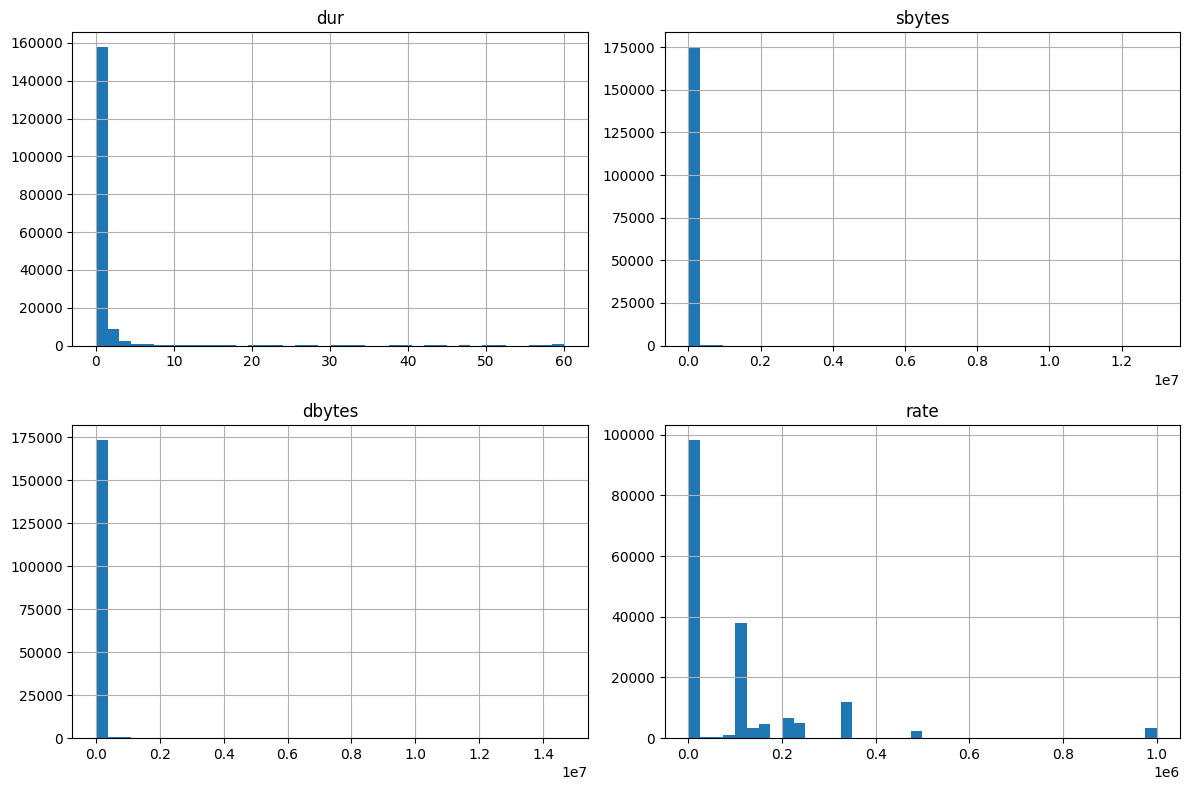

In [27]:
# Plot distributions of selected numerical features
features = ["dur", "sbytes", "dbytes", "rate"]

train_df[features].hist(figsize=(12, 8), bins=40)
plt.tight_layout()
plt.show()

## 25. Feature Correlation

Let's check how numerical features are correlated with each other and with the target label.


sttl                 0.692741
ct_state_ttl         0.577704
ct_dst_sport_ltm     0.357213
rate                 0.337979
ct_src_dport_ltm     0.305579
ct_dst_src_ltm       0.303855
ct_src_ltm           0.238225
ct_dst_ltm           0.229887
ct_srv_src           0.229044
ct_srv_dst           0.228046
sload                0.182870
ackdat               0.097364
dttl                 0.095049
tcprtt               0.081584
synack               0.058299
dur                  0.036175
sbytes               0.018576
ct_flw_http_mthd     0.015800
trans_depth          0.010801
sloss               -0.000640
sjit                -0.007069
smean               -0.010798
ct_ftp_cmd          -0.011055
is_ftp_login        -0.011055
response_body_len   -0.021361
dinpkt              -0.022887
spkts               -0.052178
djit                -0.060870
dbytes              -0.076871
dloss               -0.094685
dpkts               -0.118591
sinpkt              -0.176110
is_sm_ips_ports     -0.184679
dtcpb     

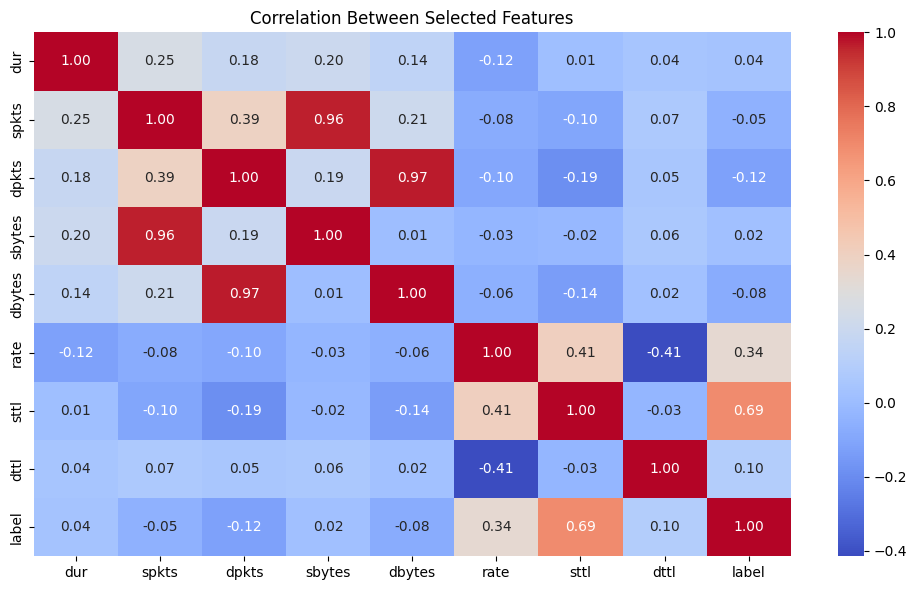

In [28]:
# Correlation with the target label
correlations = train_df.select_dtypes(include="number").corr()["label"]
print(correlations.drop(["label", "id"]).sort_values(ascending=False))

# Correlation heatmap for selected features
features = ["dur", "spkts", "dpkts", "sbytes", "dbytes", "rate", "sttl", "dttl", "label"]

plt.figure(figsize=(10, 6))
sns.heatmap(train_df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Selected Features")
plt.tight_layout()
plt.show()

## 26. Attack Category Distribution

Let's see how the different attack categories are distributed in the training dataset.


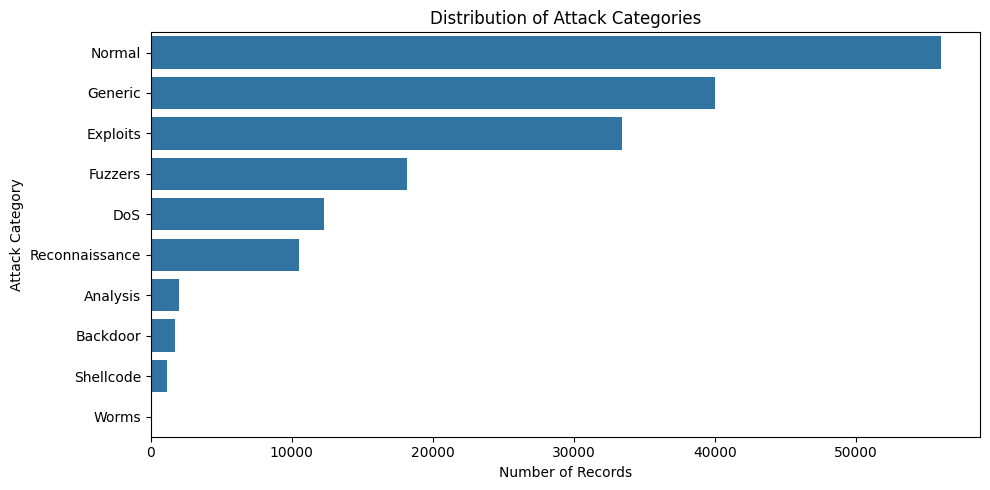

In [29]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=train_df,
    y="attack_cat",
    order=train_df["attack_cat"].value_counts().index
)

plt.title("Distribution of Attack Categories")
plt.xlabel("Number of Records")
plt.ylabel("Attack Category")
plt.tight_layout()
plt.show()

## 27. Key Findings

* Both datasets contain no missing values or duplicate rows.
* Training and testing datasets have matching columns.
* The target classes are imbalanced, with more attack records in the training set.
* Several numerical features are highly right-skewed.
* `sttl` and `ct_state_ttl` have the strongest positive correlations with the target among the numerical features examined.
* The dataset contains multiple attack categories, with some categories having far fewer records than others.
